# Money demand (Denmark) — ARDL with makystats

**Series.** Danish quarterly money-demand data in `data/danish_money.csv` (`lrm`, `lry`, `ibo`, …).

**Order selection (case 3).** On this short sample:

| Criterion | Preferred |
|-----------|-----------|
| **BIC** | `ARDL(1; 0,0)` — one lag of money; income and the bond rate **contemporaneous only** |
| **AIC** | `ARDL(3; 1,0)` — richer lags on money and one lag of income |

Main reported model: **BIC → ARDL(1, 0)** with `order=0` for both regressors.

A fixed tutorial choice such as ARDL(2, 1) is **not** IC-optimal here (worse BIC than (1;0,0) and (2;1,0)).


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from makystats import ardl, select_ardl_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

## 2. Data


In [3]:
df = pd.read_csv("data/danish_money.csv", index_col=0, parse_dates=True)
df.index = pd.PeriodIndex(df.index, freq="Q")
y = df["lrm"]
x = df[["lry", "ibo"]]
print(df.head())
print(y.index[0], "→", y.index[-1], f"({len(y)} obs.)")

              lrm       lry       lpy       ibo     ide
period                                                 
1974Q1  11.632550  5.903658 -0.618736  0.154736  0.0940
1974Q2  11.604152  5.873820 -0.580748  0.177991  0.0955
1974Q3  11.581521  5.837818 -0.542848  0.170565  0.0955
1974Q4  11.601847  5.812255 -0.504604  0.152227  0.0955
1975Q1  11.586305  5.803945 -0.486458  0.134228  0.0885
1974Q1 → 1987Q3 (55 obs.)


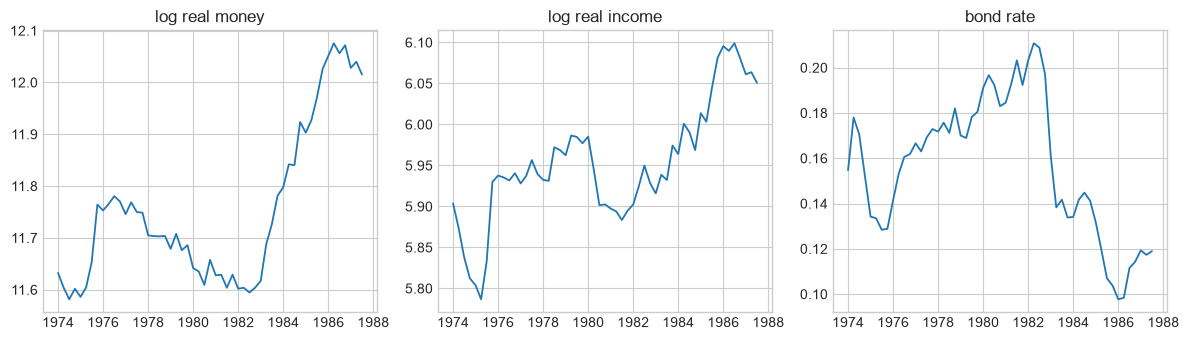

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, title in zip(axes, ["lrm", "lry", "ibo"], ["log real money", "log real income", "bond rate"]):
    ax.plot(df[col].to_timestamp(), lw=1.3)
    ax.set_title(title)
fig.tight_layout()
plt.show()

## 3. Order selection


In [5]:
table = select_ardl_order(
    y, x=x, maxlag=3, maxorder=2, case=3, ic="bic", verbose=False
)
print(table.head(8))
print("Best (BIC):", table.index[0])


              p                 order         aic         bic        hqic  \
ARDL(1; 0,0)  1  {'lry': 0, 'ibo': 0} -247.876842 -239.920906 -244.808550   
ARDL(1; 1,0)  1  {'lry': 1, 'ibo': 0} -248.423859 -238.478939 -244.588493   
ARDL(2; 1,0)  2  {'lry': 1, 'ibo': 0} -250.281690 -238.459938 -245.735614   
ARDL(3; 1,0)  3  {'lry': 1, 'ibo': 0} -251.178235 -237.519529 -245.941810   
ARDL(2; 2,0)  2  {'lry': 2, 'ibo': 0} -250.545633 -236.753589 -245.241878   
ARDL(2; 0,0)  2  {'lry': 0, 'ibo': 0} -246.525348 -236.673889 -242.736952   
ARDL(1; 0,1)  1  {'lry': 0, 'ibo': 1} -245.876845 -235.931924 -242.041479   
ARDL(2; 1,1)  2  {'lry': 1, 'ibo': 1} -248.736415 -234.944372 -243.432660   

                      ll  n_obs  case  q_lry  q_ibo    q  
ARDL(1; 0,0)  127.938421     54     3      0      0  0.0  
ARDL(1; 1,0)  129.211929     54     3      1      0  NaN  
ARDL(2; 1,0)  131.140845     53     3      1      0  NaN  
ARDL(3; 1,0)  132.589118     52     3      1      0  NaN  
ARDL(2; 2,0

### Reading the table

- **ARDL(1; 0,0)** minimises BIC: parsimonious levels relation.
- AIC may prefer **ARDL(3; 1,0)** (more short-run dynamics in money / income).
- Long-run elasticities stay in the expected region (income ≈ 1, rate < 0) across these top models.


## 4. Main model: ARDL(1, 0), case 3


In [6]:
res = ardl(y, x=x, lags=1, order=0, case=3).fit(verbose=False)
print(res.summary())


                              ARDL Model Results                              
Dep. Variable: lrm                                        No. Observations: 54
Model:         ARDL(1, 0, 0)                         Log Likelihood:   127.938
Method:        OLS (conditional)                   S.D. of innov.:   0.0228496
Case (PSS):    3 (Constant)                         AIC:              -247.877
Date:          Tue, 27 Oct 2026                     BIC:              -239.921
Time:          17:39:30                             HQIC:             -244.809
             coef    std err          t      P>|t|     [0.025     0.975]
const      2.0538     0.3981     5.1590     0.0000     1.2542     2.8534
lrm.L1     0.6424     0.0606    10.6023     0.0000     0.5207     0.7641
lry.L0     0.3939     0.0977     4.0312     0.0002     0.1976     0.5902
ibo.L0    -1.2164     0.1669    -7.2894     0.0000    -1.5516    -0.8812

Test of Normality
----------------------------------------
 Jarque-Bera   P-value

### Interpretation

- **Bounds:** F is typically well above the I(1) 5% critical values on this sample.
- **`lry`:** income elasticity near **1**.
- **`ibo`:** negative opportunity-cost effect on money demand.


## 5. UECM (Conditional EC) and bounds test

`summary_uecm()` reports the **conditional error-correction** form (levels of \(y\) and \(x\) lagged, short-run differences) and the **long-run multipliers** \(\theta\).

`summary_bounds()` is the Pesaran / Narayan **F-bounds** test for a levels relationship.


In [7]:
print(res.summary_uecm())
print(res.summary_bounds())


                              UECM Model Results                              
Dep. Variable: D.lrm                                      No. Observations: 54
Model:         UECM(1, …)                            Log Likelihood:   127.938
Method:        OLS (reparam. ARDL)                  AIC:              -247.877
Case (PSS):    3 (Constant)                         BIC:              -239.921
               coef    std err          t      P>|t|     [0.025     0.975]
const        2.0538     0.3981     5.1590     0.0000     1.2534     2.8542
lrm.L1      -0.3576     0.0606    -5.9018     0.0000    -0.4794    -0.2358
lry.L1       0.3939     0.0977     4.0312     0.0002     0.1974     0.5904
D.lry.L0     0.3939     0.0977     4.0312     0.0002     0.1974     0.5904
ibo.L1      -1.2164     0.1669    -7.2894     0.0000    -1.5519    -0.8809
D.ibo.L0    -1.2164     0.1669    -7.2894     0.0000    -1.5519    -0.8809

Long run (multiplicateurs)
----------------------------------------
           

## 6. ECM and diagnostics


                            ECM (Error Correction)                            
               coef    std err          t      P>|t|
COINTEQ     -0.3576     0.0654    -5.4651     0.0000
D.lry.L0     0.3939     0.1279     3.0790     0.0034
D.ibo.L0    -1.2164     0.3173    -3.8341     0.0004
const        2.0538     0.3749     5.4787     0.0000

Half-life (approx.): 1.566
α=-0.3576 (p=1.465e-06) : retour vers l'équilibre (α<0)
None


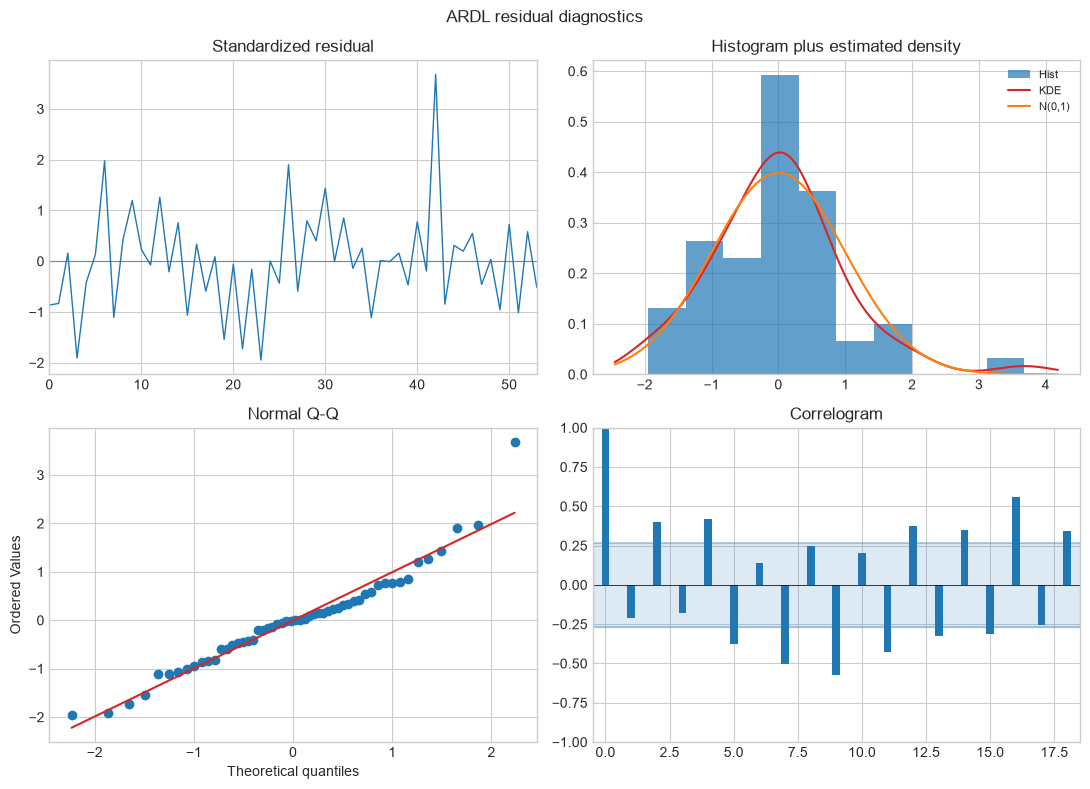

In [8]:
print(res.summary_ecm())
fig = res.plot_diagnostics()
plt.show()


## 7. Optional: AIC-style ARDL(3; 1, 0)


In [9]:
res_aic = ardl(y, x=x, lags=3, order={"lry": 1, "ibo": 0}, case=3).fit(verbose=False)
print(res_aic.summary_bounds())
print("Long run:\n", res_aic.long_run)


                       Bounds test (Pesaran / Narayan)                        
case=3 (Constant)    k=2    n=52    F=6.153563
t-stat (y.L1) = -4.437311
restrictions (q) = 3

Pesaran, Shin & Smith (2001) — asymptotic
          I(0)       I(1)     F-stat       Décision
1%      4.2900     5.6100     6.1536  Cointégration
5%      3.2300     4.3500     6.1536  Cointégration
10%     2.7200     3.7700     6.1536  Cointégration

Narayan (2005) — finite sample
          I(0)       I(1)     F-stat           Décision
1%      5.7730     7.1730     6.1536  Zone d'indécision
5%      4.0370     5.1500     6.1536      Cointégration
10%     3.3120     4.2970     6.1536      Cointégration

Synthèse (5%) : cointégration (rejette H0 : pas de relation de long terme)
None
Long run:
 const    7.052197
lry      0.893800
ibo     -3.821235
Name: long_run, dtype: float64


## Takeaways

1. Select orders with **BIC/AIC** on this small sample; do not freeze ARDL(2,1) by habit.
2. BIC’s **ARDL(1; 0,0)** is enough to illustrate bounds + long-run money demand.
3. Always report **case** (here 3) together with \((p, q)\).
